Applied Machine Learning and Big Data Strategy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Uploading dataset
df = pd.read_csv('/content/alzheimers_disease_data.csv')

In [3]:
#Checking for missing variables
check_missing_data = df[df.isnull().any(axis=1)]
print(check_missing_data)

print(df.isnull().sum().sum())

      Age  Gender  Ethnicity   BMI Smoking  AlcoholConsumption  \
0      73    Male  Caucasian  22.9      No                13.3   
1      89    Male  Caucasian  26.8      No                 4.5   
2      73    Male      Other  17.8      No                19.6   
3      74  Female  Caucasian  33.8     Yes                12.2   
4      89    Male  Caucasian  20.7      No                18.5   
...   ...     ...        ...   ...     ...                 ...   
2144   61    Male  Caucasian  39.1      No                 1.6   
2145   75    Male  Caucasian  17.9      No                18.8   
2146   77    Male  Caucasian  15.5      No                 4.6   
2147   78  Female      Other  15.3      No                 8.7   
2148   72    Male  Caucasian  33.3      No                 7.9   

      PhysicalActivity  DietQuality  SleepQuality  FamilyHistoryAlzheimers  \
0                  6.3          1.3           9.0                        0   
1                  7.6          0.5           7.2  

# Descriptive Statistics

In [4]:
# Summary statistics for numerical features
print(df.describe())


               Age          BMI  AlcoholConsumption  PhysicalActivity  \
count  2149.000000  2149.000000         2149.000000       2149.000000   
mean     74.908795    27.655468           10.072313          4.919916   
std       8.990221     7.218950            5.764539          2.857300   
min      60.000000    15.000000            0.000000          0.000000   
25%      67.000000    21.600000            5.200000          2.600000   
50%      75.000000    27.800000           10.000000          4.800000   
75%      83.000000    33.900000           15.200000          7.400000   
max      90.000000    40.000000           20.000000         10.000000   

       DietQuality  SleepQuality  FamilyHistoryAlzheimers  \
count  2149.000000   2149.000000              2149.000000   
mean      4.993904      7.050861                 0.252210   
std       2.909236      1.765805                 0.434382   
min       0.000000      4.000000                 0.000000   
25%       2.500000      5.500000     

In [5]:
# Mean, Median, and Mode
numeric_df = df.select_dtypes(include=['number'])

# Repeat statistics for numeric data
mean_values = numeric_df.mean()
median_values = numeric_df.median()
mode_values = numeric_df.mode().iloc[0]
range_values = numeric_df.max() - numeric_df.min()
variance_values = numeric_df.var()
std_dev_values = numeric_df.std()

print(" Mean:\n", mean_values)
print(" Median:\n", median_values)
print(" Mode:\n", mode_values)
print(" Range:\n", range_values)
print(" Variance:\n", variance_values)
print(" Standard Deviation:\n", std_dev_values)

 Mean:
 Age                            74.908795
BMI                            27.655468
AlcoholConsumption             10.072313
PhysicalActivity                4.919916
DietQuality                     4.993904
SleepQuality                    7.050861
FamilyHistoryAlzheimers         0.252210
CardiovascularDisease           0.144253
Diabetes                        0.150768
Depression                      0.200558
HeadInjury                      0.092601
Hypertension                    0.148906
CholesterolTotal              225.197859
CholesterolLDL                124.336668
MMSE                           14.755793
MemoryComplaints                0.208004
ADL                             4.982876
Disorientation                  0.158213
PersonalityChanges              0.150768
DifficultyCompletingTasks       0.158678
Forgetfulness                   0.301536
Diagnosis                       0.357841
Unnamed: 25                          NaN
Unnamed: 26                  1074.500000
dtype: f

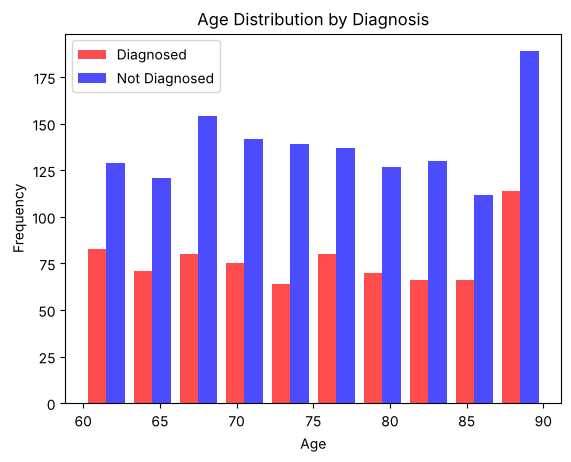

In [6]:
#1. Age distribution with diagonised with Alzheimer's disease

diagnosed = df[df['Diagnosis'] == 1] ['Age']
not_diagnosed = df[df['Diagnosis'] == 0]['Age']

plt.hist([diagnosed, not_diagnosed],
         bins=10,
         label=['Diagnosed', 'Not Diagnosed'],
         color=['red', 'blue'],
         alpha=0.7)
plt.title('Age Distribution by Diagnosis')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

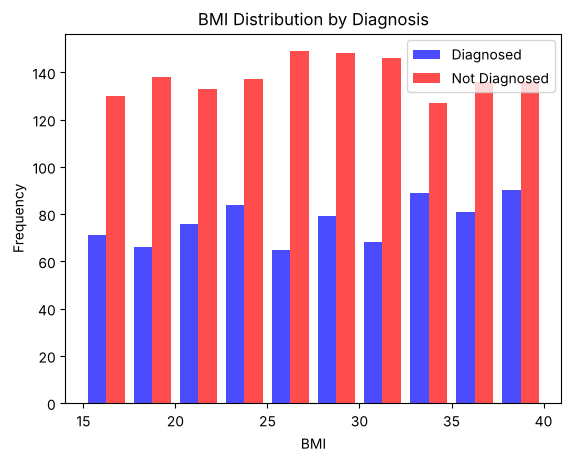

In [7]:
#2. BMI Distribution by Diagnosis (Histogram)

diagnosed_bmi = df[df['Diagnosis'] == 1]['BMI']
not_diagnosed_bmi = df[df['Diagnosis'] == 0]['BMI']

plt.hist([diagnosed_bmi, not_diagnosed_bmi],
         bins=10,
         label=['Diagnosed', 'Not Diagnosed'],
         color=['blue', 'red'],
         alpha=0.7)
plt.title('BMI Distribution by Diagnosis')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.legend()
plt.show()

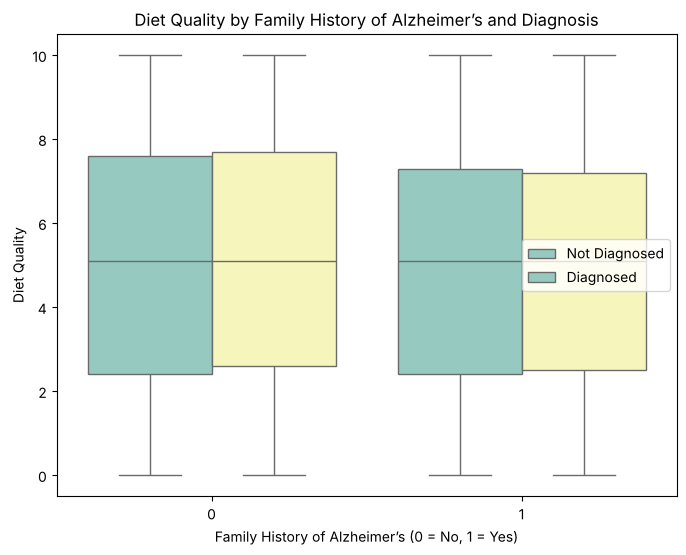

In [8]:
#3. Diet Quality by Family History of Alzheimers and Diagnosis
plt.figure(figsize=(8, 6))
sns.boxplot(x='FamilyHistoryAlzheimers', y='DietQuality', hue='Diagnosis', data=df, palette='Set3')
plt.title('Diet Quality by Family History of Alzheimer’s and Diagnosis')
plt.xlabel('Family History of Alzheimer’s (0 = No, 1 = Yes)')
plt.ylabel('Diet Quality')
plt.legend(['Not Diagnosed', 'Diagnosed'])
plt.show()

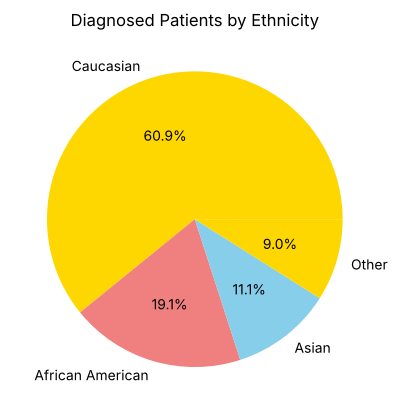

In [9]:
#4. Diagnosed patients by Ethnicity
ethnicity_diagnosis = df[df['Diagnosis'] == 1]['Ethnicity'].value_counts()

plt.pie(ethnicity_diagnosis, labels=ethnicity_diagnosis.index, autopct='%1.1f%%', colors=['gold', 'lightcoral', 'skyblue'])
plt.title('Diagnosed Patients by Ethnicity')
plt.show()

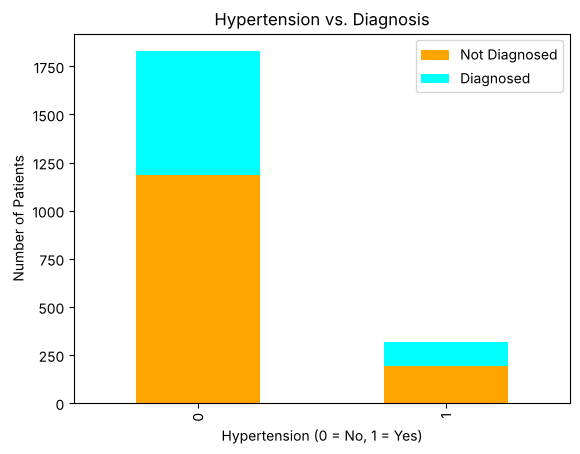

In [10]:
#5. Hypertension vs Diagnosis
hypertension_vs_diagnosis = df.groupby(['Hypertension', 'Diagnosis']).size().unstack()

hypertension_vs_diagnosis.plot(kind='bar', stacked=True, color=['orange', 'cyan'])
plt.title('Hypertension vs. Diagnosis')
plt.xlabel('Hypertension (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(['Not Diagnosed', 'Diagnosed'])
plt.show()

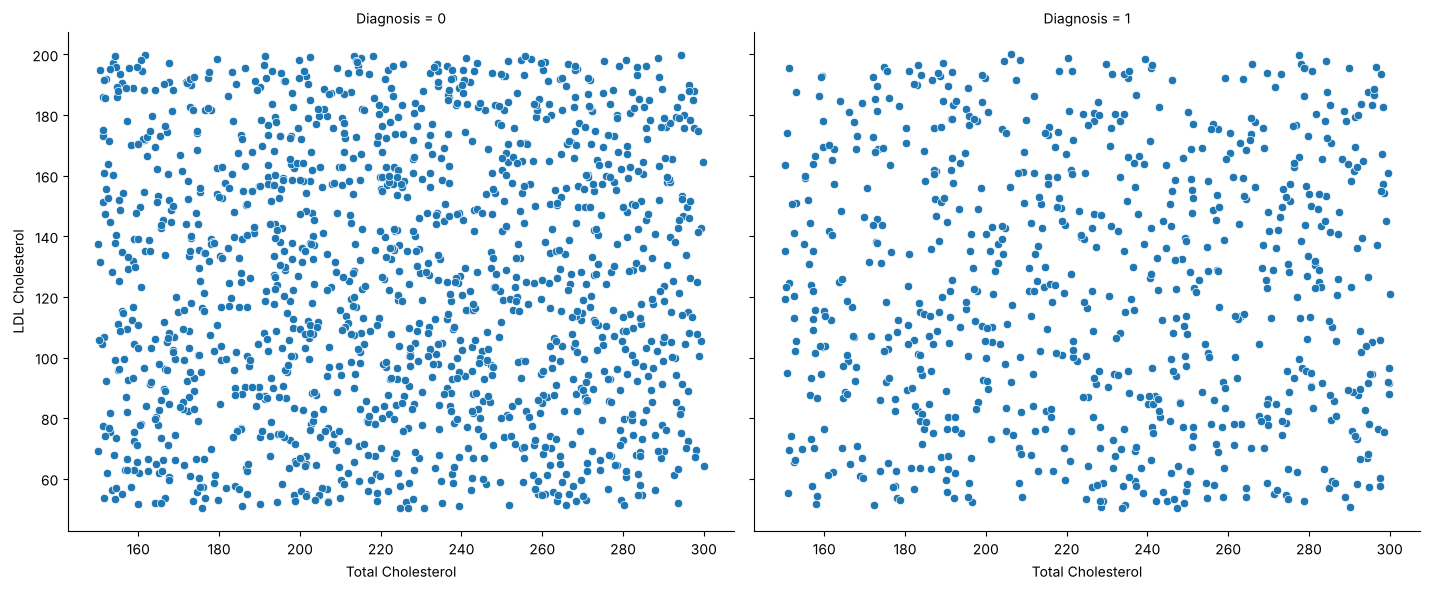

In [11]:
#6. Cholesterol Levels (Total vs. LDL) by Diagnosis (Scatter Plot)
g = sns.FacetGrid(df, col='Diagnosis', height=6, aspect=1.2, palette="coolwarm")
g.map(sns.scatterplot, 'CholesterolTotal', 'CholesterolLDL')
g.set_axis_labels('Total Cholesterol', 'LDL Cholesterol')
g.set_titles(col_template='Diagnosis = {col_name}')
plt.show()


/tmp/ipykernel_346/1670696042.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Diagnosis', y='ADL', data=df, palette='cool')


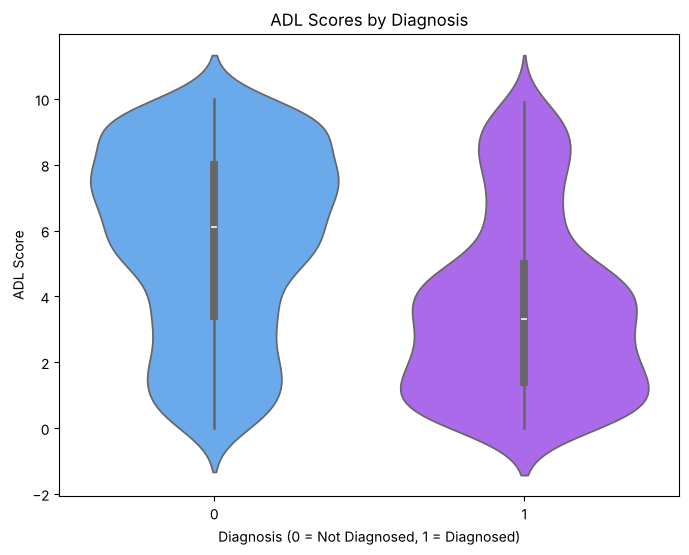

In [12]:
#7. ADL (Activities of Daily Living) Scores by Diagnosis (Violin Plot)
plt.figure(figsize=(8, 6))
sns.violinplot(x='Diagnosis', y='ADL', data=df, palette='cool')
plt.title('ADL Scores by Diagnosis')
plt.xlabel('Diagnosis (0 = Not Diagnosed, 1 = Diagnosed)')
plt.ylabel('ADL Score')
plt.show()

/tmp/ipykernel_346/2267778308.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Diagnosis', y='MMSE', palette='coolwarm')


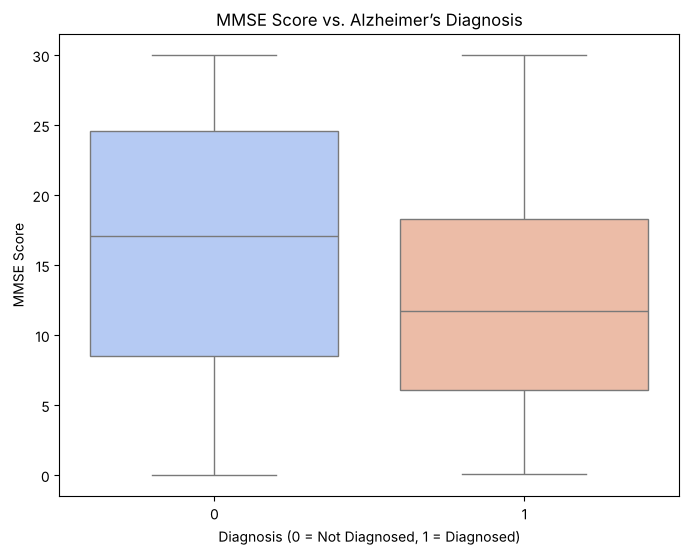

In [13]:
#8. MMSE Score vs. Diagnosis
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Diagnosis', y='MMSE', palette='coolwarm')
plt.title('MMSE Score vs. Alzheimer’s Diagnosis')
plt.xlabel('Diagnosis (0 = Not Diagnosed, 1 = Diagnosed)')
plt.ylabel('MMSE Score')
plt.show()


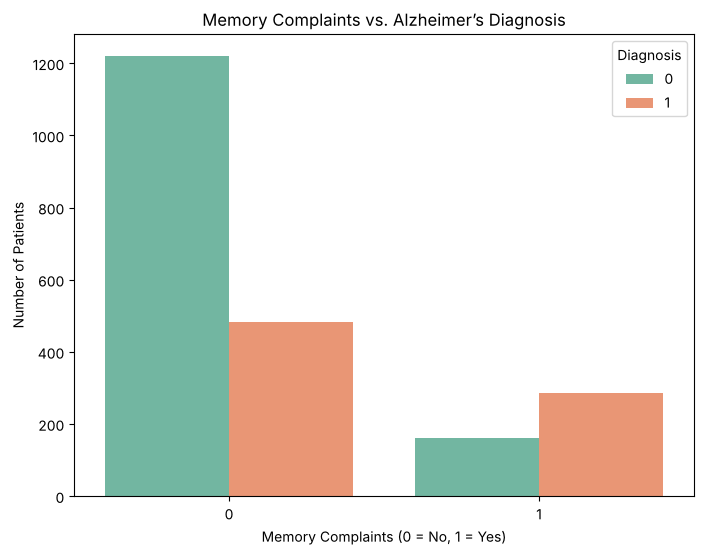

In [14]:
#9. Memory Complaints vs. Diagnosis
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='MemoryComplaints', hue='Diagnosis', palette='Set2')
plt.title('Memory Complaints vs. Alzheimer’s Diagnosis')
plt.xlabel('Memory Complaints (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis')
plt.show()

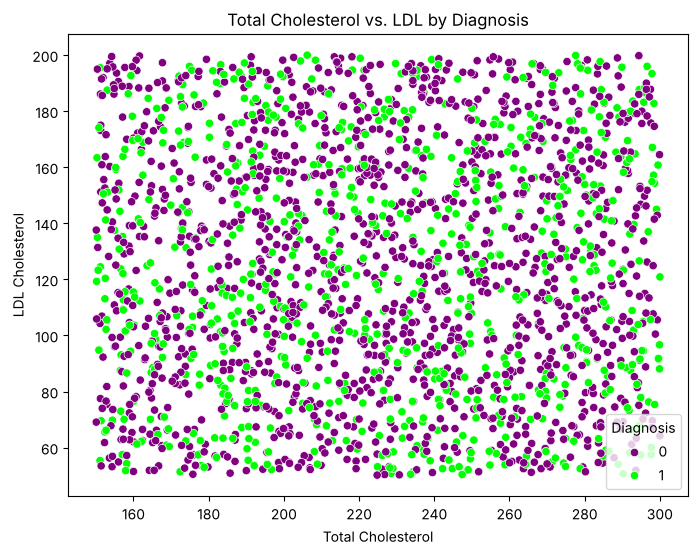

In [15]:
#10. Cholesterol Total vs. LDL Cholesterol by Diagnosis
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='CholesterolTotal', y='CholesterolLDL', hue='Diagnosis', palette=['purple', 'lime'])
plt.title('Total Cholesterol vs. LDL by Diagnosis')
plt.xlabel('Total Cholesterol')
plt.ylabel('LDL Cholesterol')
plt.legend(title='Diagnosis')
plt.show()

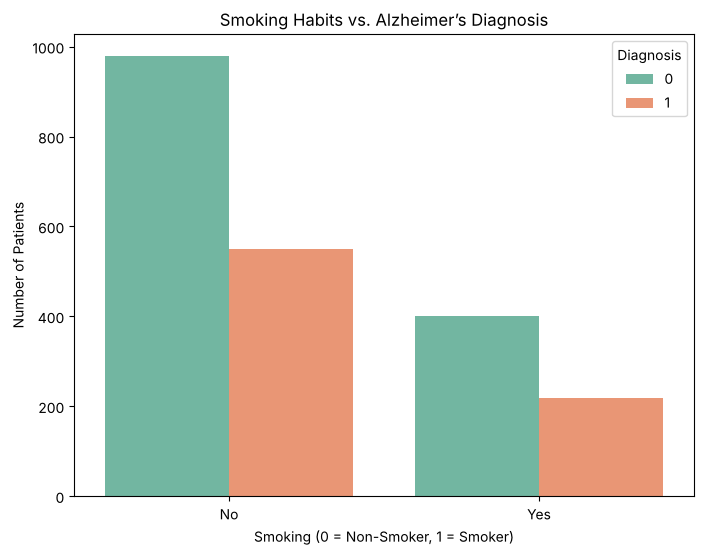

In [16]:
#11. Smoking vs. Diagnosis (Stacked Bar Chart)
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Smoking', hue='Diagnosis', palette='Set2')
plt.title('Smoking Habits vs. Alzheimer’s Diagnosis')
plt.xlabel('Smoking (0 = Non-Smoker, 1 = Smoker)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis')
plt.show()

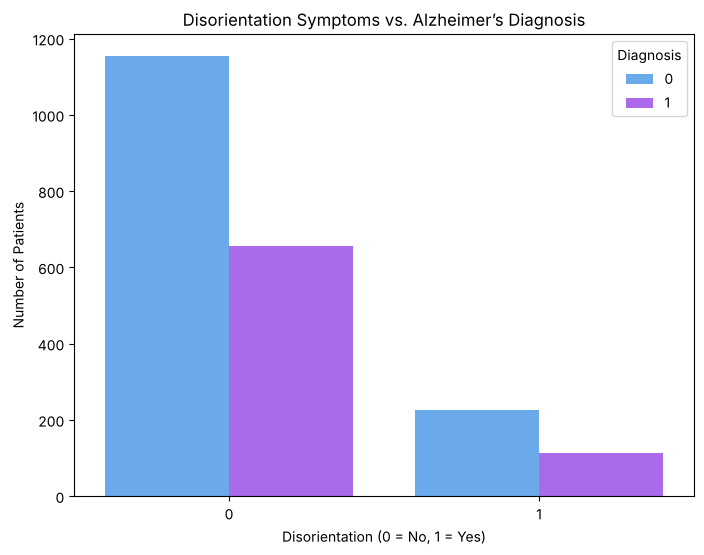

In [17]:
#12. Disorientation vs. Alzheimer’s Diagnosis
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Disorientation', hue='Diagnosis', palette='cool')
plt.title('Disorientation Symptoms vs. Alzheimer’s Diagnosis')
plt.xlabel('Disorientation (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis')
plt.show()

/tmp/ipykernel_346/3473617940.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=df, x='Diagnosis', y='AlcoholConsumption', palette='deep', size=4)


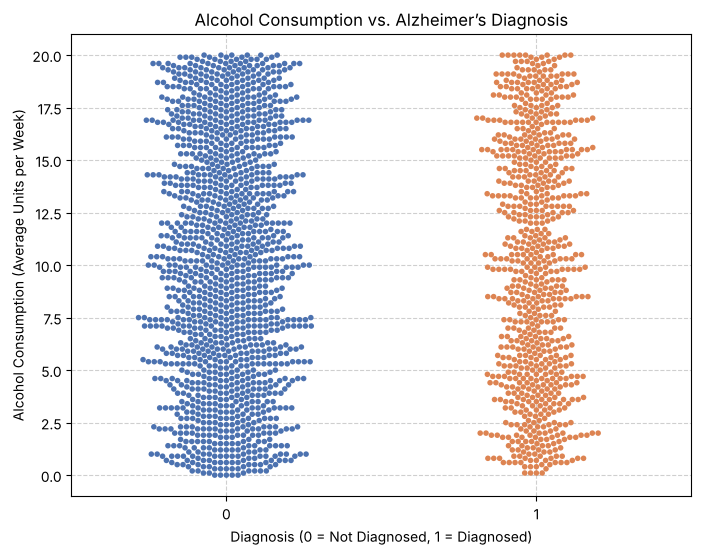

In [18]:
#13. Swarm Plot (Alcohol Consumption vs. Diagnosis)

plt.figure(figsize=(8, 6))
sns.swarmplot(data=df, x='Diagnosis', y='AlcoholConsumption', palette='deep', size=4)
plt.title('Alcohol Consumption vs. Alzheimer’s Diagnosis')
plt.xlabel('Diagnosis (0 = Not Diagnosed, 1 = Diagnosed)')
plt.ylabel('Alcohol Consumption (Average Units per Week)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

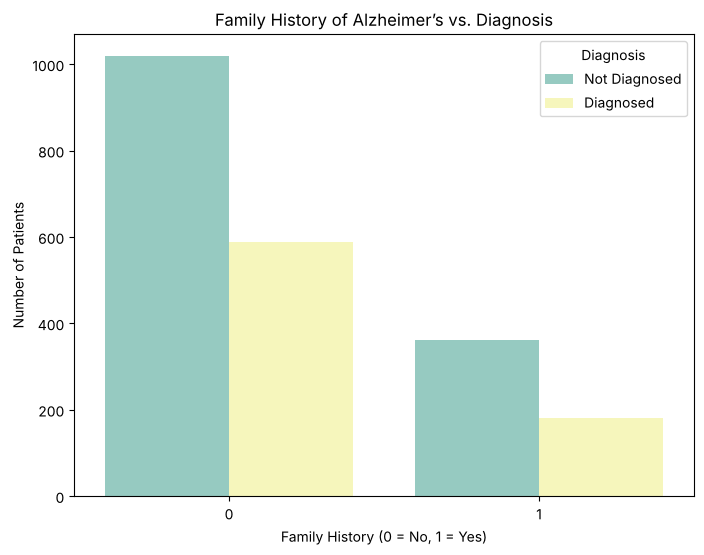

In [19]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='FamilyHistoryAlzheimers', hue='Diagnosis', palette='Set3')
plt.title('Family History of Alzheimer’s vs. Diagnosis')
plt.xlabel('Family History (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis', labels=['Not Diagnosed', 'Diagnosed'])
plt.show()

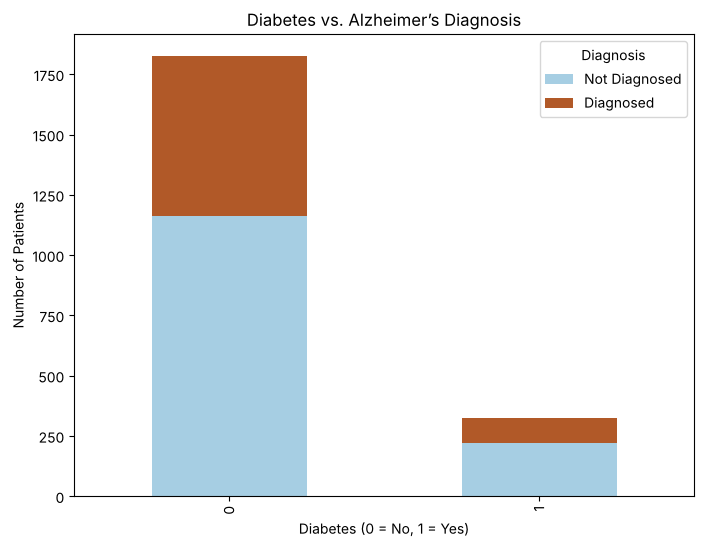

In [20]:
cross_tab_diabetes = pd.crosstab(df['Diabetes'], df['Diagnosis'])

cross_tab_diabetes.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='Paired')
plt.title('Diabetes vs. Alzheimer’s Diagnosis')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis', labels=['Not Diagnosed', 'Diagnosed'])
plt.show()

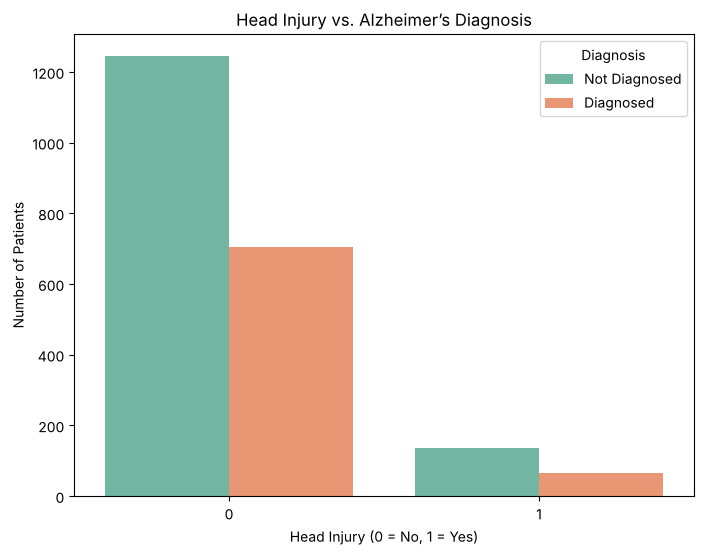

In [21]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='HeadInjury', hue='Diagnosis', palette='Set2')
plt.title('Head Injury vs. Alzheimer’s Diagnosis')
plt.xlabel('Head Injury (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.legend(title='Diagnosis', labels=['Not Diagnosed', 'Diagnosed'])
plt.show()

# **Machine Learning with parameter tuning**


*   Random Forest
*   Support Vector Machine



In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV

In [23]:
#Converting
# Gender: Male = 0, Female = 1
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

# Smoking: No = 0, Yes = 1
df['Smoking'] = df['Smoking'].map({'No': 0, 'Yes': 1})

# Ethnicity: Assign integers to each unique category
df['Ethnicity'] = df['Ethnicity'].map({
    'Caucasian': 0,
    'African American': 1,
    'Asian': 2,
    'Other': 3
})

# Define feature variables (X) and target variable (y)
X = df[['Age', 'Gender', 'Ethnicity', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
          'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury',
          'Hypertension', 'CholesterolTotal', 'CholesterolLDL', 'MMSE', 'MemoryComplaints', 'ADL', 'Disorientation',
          'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']]

y = df['Diagnosis']  # Target variable (e.g., diagnosis: 0 = no disease, 1 = Alzheimer's)

# Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#  split data
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1719, 24)
X_test shape: (430, 24)
y_train shape: (1719,)
y_test shape: (430,)


In [24]:
# Train the Random Forest model on the training data
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rf_model.predict(X_test)

# Print the predictions (first 10 as an example)
print("Predictions on X_test (first 10):", y_pred[:10])

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy)

# Display detailed classification report and confusion matrix
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Predictions on X_test (first 10): [0 0 1 1 0 0 1 0 0 1]

Model Accuracy: 0.7511627906976744

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.83      0.81       276
           1       0.67      0.60      0.63       154

    accuracy                           0.75       430
   macro avg       0.73      0.72      0.72       430
weighted avg       0.75      0.75      0.75       430


Confusion Matrix:
 [[230  46]
 [ 61  93]]


In [25]:
#random forest with different parameters

# Gender, Smoking and Ethnicity were already converted to numbers in the cell above,
# so copy them across (mapping them a second time would turn every value into NaN)
df['Gender_encoded'] = df['Gender']
df['Smoking_encoded'] = df['Smoking']
df['Ethnicity_encoded'] = df['Ethnicity']

# Define new feature set (X_new) and target (y_new)
X_new = df[['Age', 'Gender_encoded', 'Ethnicity_encoded', 'BMI', 'Smoking_encoded', 'AlcoholConsumption', 'PhysicalActivity',
            'DietQuality', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression',
            'HeadInjury', 'Hypertension', 'CholesterolTotal', 'CholesterolLDL', 'MMSE', 'MemoryComplaints', 'ADL',
            'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']]

y_new = df['Diagnosis']  # Target variable which is 0 = No disease, 1 = Alzheimer's

# Split the new dataset
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new, y_new, test_size=0.2, random_state=42)

# Print new split sizes
print("X_train_new shape:", X_train_new.shape)
print("X_test_new shape:", X_test_new.shape)
print("y_train_new shape:", y_train_new.shape)
print("y_test_new shape:", y_test_new.shape)

# Define the parameter grid for hyperparameter tuning
param_grid_new = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

# Perform hyperparameter tuning using new variables
rf_new = RandomForestClassifier(random_state=42, oob_score=True, bootstrap=True)
grid_search_new = GridSearchCV(estimator=rf_new, param_grid=param_grid_new,
                               cv=5, n_jobs=-1, verbose=2, scoring='f1')

# Fit the grid search to find the best hyperparameters
grid_search_new.fit(X_train_new, y_train_new)

# Get the best model and parameters
best_params_new = grid_search_new.best_params_
print("\nBest Parameters:", best_params_new)
print("Best F1 Score:", grid_search_new.best_score_)

# Train the final Random Forest model with best parameters
rf_model_new = RandomForestClassifier(**best_params_new, random_state=42)
rf_model_new.fit(X_train_new, y_train_new)

# Make predictions on the test data
y_pred_new = rf_model_new.predict(X_test_new)

# Evaluate new model performance
accuracy_new = accuracy_score(y_test_new, y_pred_new)
print("\nModel Accuracy:", accuracy_new)
print("\nClassification Report:\n", classification_report(y_test_new, y_pred_new))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_new, y_pred_new))


X_train_new shape: (1719, 24)
X_test_new shape: (430, 24)
y_train_new shape: (1719,)
y_test_new shape: (430,)
Fitting 5 folds for each of 432 candidates, totalling 2160 fits


[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s
[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s


[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s
[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s


[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s


[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.6s
[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.5s


[CV] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.5s


... (1,564 outputs left out)

[CV] END class_weight=balanced, max_depth=40, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=300; total time=   0.9s


[CV] END class_weight=balanced, max_depth=40, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=300; total time=   0.8s



Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}
Best F1 Score: 0.7289689279611979



Model Accuracy: 0.7837209302325582

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.76      0.82       276
           1       0.66      0.83      0.73       154

    accuracy                           0.78       430
   macro avg       0.77      0.79      0.78       430
weighted avg       0.81      0.78      0.79       430


Confusion Matrix:
 [[209  67]
 [ 26 128]]


In [26]:
# Import necessary libraries
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a pipeline with imputation, scaling, and SVM
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),  # Replace NaN with mean values
    ('scaler', StandardScaler()),                # Scale features
    ('svm', SVC(random_state=42))               # SVM classifier
])

# Train the SVM model on the training data
svm_pipeline.fit(X_train, y_train)

# Make predictions on the test data
y_pred = svm_pipeline.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy)

# Display detailed classification report and confusion matrix
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Optional: Hyperparameter tuning
param_grid = {
    'imputer__strategy': ['mean', 'median'],  # Try different imputation strategies
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 'auto', 0.1, 0.01],
    'svm__kernel': ['rbf', 'linear']
}



Model Accuracy: 0.7209302325581395

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.85      0.80       276
           1       0.64      0.49      0.56       154

    accuracy                           0.72       430
   macro avg       0.70      0.67      0.68       430
weighted avg       0.71      0.72      0.71       430


Confusion Matrix:
 [[234  42]
 [ 78  76]]


# **XAI Techniques**
SHAP, LIME, and PFI

In [27]:
#Installing and importing packages
import shap
from sklearn.inspection import permutation_importance

!pip install lime -q
import lime
import lime.lime_tabular as lime_tabular

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [28]:
#PFI

pfi_results = permutation_importance(rf_model_new, X_test_new, y_test_new, n_repeats=10, random_state=42)

# Print feature importance scores
for feature, importance in zip(X.columns, pfi_results.importances_mean):
    print(f"{feature}: {importance:.4f}")

Age: 0.0042
Gender: 0.0002
Ethnicity: -0.0005
BMI: 0.0042
Smoking: -0.0002
AlcoholConsumption: 0.0030
PhysicalActivity: 0.0056
DietQuality: 0.0016
SleepQuality: 0.0009
FamilyHistoryAlzheimers: -0.0002
CardiovascularDisease: 0.0007
Diabetes: 0.0026
Depression: 0.0002
HeadInjury: 0.0000
Hypertension: -0.0002
CholesterolTotal: 0.0012
CholesterolLDL: -0.0033
MMSE: 0.1181
MemoryComplaints: 0.0674
ADL: 0.1400
Disorientation: -0.0007
PersonalityChanges: 0.0016
DifficultyCompletingTasks: 0.0002
Forgetfulness: 0.0000


In [29]:
# LIME
explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train_new.values,
    feature_names=X_new.columns,
    class_names=['No Alzheimer', 'Alzheimer'],
    mode='classification'
)

# Explain a single prediction
idx = 5  # Example test sample index
exp = explainer.explain_instance(X_test_new.iloc[idx].values, rf_model_new.predict_proba)

# Show explanation
exp.show_in_notebook()

/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


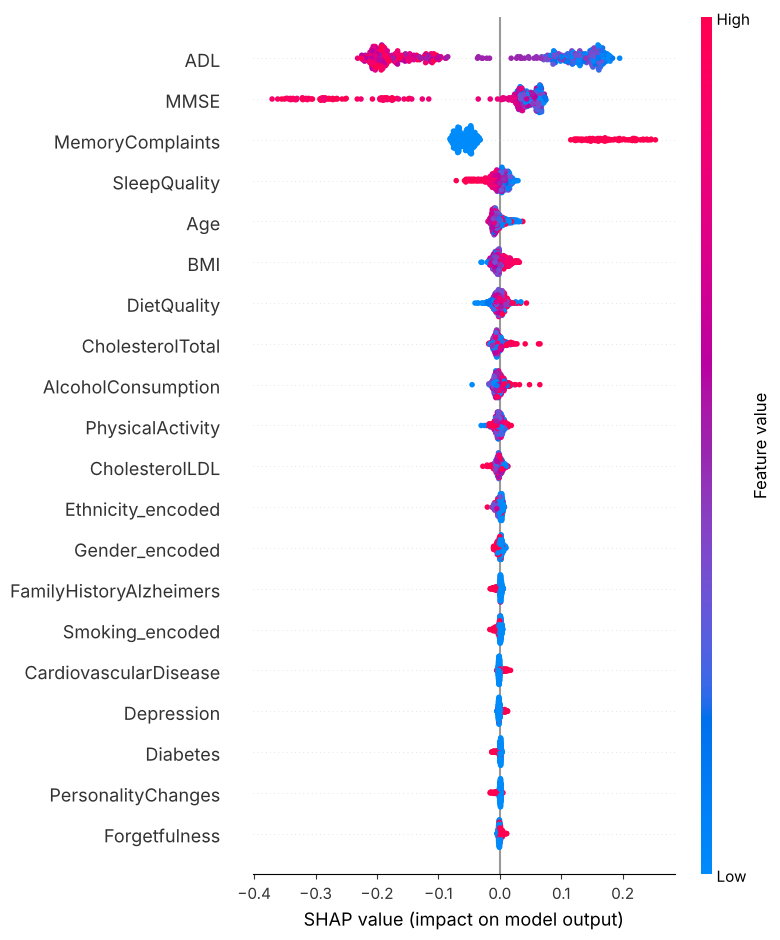

In [30]:
# SHAP values for the tuned Random Forest (the same model explained by PFI and LIME above)
explainer_shap = shap.TreeExplainer(rf_model_new)
shap_values = explainer_shap.shap_values(X_test_new)

# Keep the values for the "Alzheimer's" class (older SHAP versions return a list, newer ones a 3D array)
shap_values_alz = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]

# Summary plot for the diagnosis prediction
shap.summary_plot(shap_values_alz, X_test_new, feature_names=X_test_new.columns)
